# CS 471 Final Project Checkpoint — Q-Learning for Blackjack

**Goal:** a model-free Q-learning agent learns when to **Hit** or **Stand** by playing simulated hands, then is evaluated against fixed comparison strategies on separate games with exploration turned off.

| Rubric item | Where it is shown |
|---|---|
| Core algorithm execution | Part 2 (the update, checked against a hand calculation) and Part 3 (training trace) |
| Functional demonstration | Parts 3–5: training, learning curve, final comparison, learned policy |
| Basic correctness verification | Part 7: test suite (18 checks) with the expected behavior of each; dataset check in Part 6 |
| GitHub repository and reproducibility | `README.md`; fixed seeds in `CONFIG`; `scripts/run_experiment.py` reproduces every number |

**Instructor's required revisions:** (1) comparison strategies → Part 4; (2) evaluation on separate games without exploration → Part 4; (3) simplified rules defined → Part 1.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # make the blackjack_rl package importable

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from blackjack_rl.env import BlackjackEnv, all_states
from blackjack_rl.agent import q_learning_update, policy_from_q
from blackjack_rl.baselines import stand_on_17_policy
from blackjack_rl.optimal import optimal_policy, optimal_q_table
from blackjack_rl.experiment import (CONFIG, train_with_learning_curve, final_comparison,
                                     standard_policies, policy_disagreements)
from blackjack_rl import plots, dataset

pd.set_option("display.precision", 4)
print(json.dumps(CONFIG, indent=2))

{
  "episodes": 500000,
  "alpha": 0.01,
  "gamma": 1.0,
  "eps_start": 1.0,
  "eps_end": 0.05,
  "train_seed": 471,
  "checkpoint_every": 10000,
  "checkpoint_eval_games": 20000,
  "checkpoint_eval_seed": 1000,
  "final_eval_games": 100000,
  "final_eval_seed": 2026
}


## Part 1 — Environment and simplified rules (Required Revision #3)

| Rule | Choice |
|---|---|
| Deck | Infinite deck: each card is drawn with replacement. 2–9 face value, 10/J/Q/K = 10, Ace = 11 unless that busts, then 1 |
| Naturals | Resolved before the player acts (the dealer checks for blackjack). Player natural only = **+1** (not 3:2); dealer natural only = −1; both = 0 |
| Player actions | **Hit** or **Stand** only (no double, split, insurance, or surrender) |
| Player bust | Immediate −1; the dealer does not play |
| Dealer | Hits until 17 or more; **stands on all 17s**, including soft 17 |
| Result | Higher total wins (+1 / −1); equal totals push (0) |

**State** = (player total 4–21, dealer up-card A–10, usable Ace yes/no) → **280 decision states**, 2 actions each.
**Reward** = +1 win, −1 loss, 0 push, given at the end of the hand (every step before that gives 0). γ = 1 because only the final result matters.

One hand played with the "stand on 17+" rule, to show the simulator's output:

In [2]:
env = BlackjackEnv(seed=5)
state, reward, done = env.reset()
print(f"Player {env.player}  Dealer shows {env.dealer[0]}  -> state {state}")
while not done:
    action = stand_on_17_policy(state)
    state, reward, done = env.step(action)
    print(f"  {action:5s} -> player {env.player}, state {state}")
print(f"Dealer final hand {env.dealer}  ->  reward {reward:+d}")

Player [10, 5]  Dealer shows 10  -> state (15, 10, False)
  Hit   -> player [10, 5, 10], state (25, 10, False)
Dealer final hand [10, 6]  ->  reward -1


## Part 2 — Core algorithm: the Q-learning update

Same update equation as in HW4 Part VI:

$$Q(s,a) \leftarrow Q(s,a) + \alpha\big[\underbrace{r + \gamma \max_{a'} Q(s',a')}_{\text{target}} - Q(s,a)\big]$$

At a terminal step (a bust or a stand), there is no next state, so the target is just $r$.

**Check against a hand calculation (a blackjack example):** the player holds hard 12 against a dealer 4, hits, and lands on 16.
Current $Q(12\text{ vs }4,\text{Hit}) = -0.20$, $r = 0$, $\max_{a'} Q(16\text{ vs }4, a') = -0.30$, α = 0.1, γ = 1.

* target = 0 + 1·(−0.30) = **−0.30**
* TD error = −0.30 − (−0.20) = **−0.10**
* updated Q = −0.20 + 0.1·(−0.10) = **−0.21**

In [3]:
target, td_error, new_q = q_learning_update(q_current=-0.20, reward=0, max_next_q=-0.30, alpha=0.1, gamma=1.0)
display(pd.DataFrame({"Quantity": ["Target", "TD error", "Updated Q"],
                      "Expected (by hand)": [-0.30, -0.10, -0.21],
                      "blackjack_rl output": [target, td_error, new_q]}))

,Quantity,Expected (by hand),blackjack_rl output
0,Target,-0.30,-0.30
1,TD error,-0.10,-0.10
2,Updated Q,-0.21,-0.21


## Part 3 — Training

500,000 simulated hands with ε-greedy exploration (ε falls linearly from 1.0 to 0.05 over the first half of training) and α = 0.01.
Every 10,000 episodes, training pauses. A **frozen copy** of the Q-table plays 20,000 evaluation deals with **ε = 0**, and those games never update the Q-table.

The first few updates are shown below. Each row is one experience (s, a, r, s′) and its effect on one Q-value:

In [4]:
trace = []
Q, curve, train_rewards, curve_refs = train_with_learning_curve(CONFIG, trace=trace)
print(f"Q-table entries learned: {len(Q)}  (280 states x 2 actions = 560 possible)")
display(pd.DataFrame(trace).head(12))

Q-table entries learned: 560  (280 states x 2 actions = 560 possible)


,episode,state,action,reward,next_state,Q_before,TD_error,Q_after
0,0,"(7, 10, False)",Stand,-1,None,0.0,-1.0,-0.01
1,2,"(12, 3, False)",Hit,0,"(15, 3, False)",0.0,0.0,0.00
2,2,"(15, 3, False)",Hit,0,"(20, 3, False)",0.0,0.0,0.00
3,2,"(20, 3, False)",Hit,-1,None,0.0,-1.0,-0.01
4,3,"(13, 5, True)",Hit,0,"(19, 5, True)",0.0,0.0,0.00
5,3,"(19, 5, True)",Hit,0,"(18, 5, False)",0.0,0.0,0.00
6,3,"(18, 5, False)",Hit,0,"(20, 5, False)",0.0,0.0,0.00
7,3,"(20, 5, False)",Hit,-1,None,0.0,-1.0,-0.01
8,4,"(15, 8, False)",Hit,0,"(20, 8, False)",0.0,0.0,0.00
9,4,"(20, 8, False)",Hit,-1,None,0.0,-1.0,-0.01


**Learned Q-values vs. the exact answer.** Because the deck is infinite, the true $Q^*(s,a)$ can be computed exactly with dynamic programming, the model-based approach from HW4 Parts I–II. Q-learning never sees these numbers; they are only used to grade it.

In [5]:
q_star = optimal_q_table()
examples = [(20, 10, False), (16, 10, False), (12, 4, False), (11, 6, False), (18, 9, True), (13, 2, False)]
rows = []
for s in examples:
    rows.append({"state (total, up, ace)": s,
                 "Q stand (learned)": Q[(s, "Stand")], "Q* stand (exact)": q_star[(s, "Stand")],
                 "Q hit (learned)": Q[(s, "Hit")], "Q* hit (exact)": q_star[(s, "Hit")],
                 "learned action": policy_from_q(Q)(s), "optimal action": optimal_policy()(s)})
display(pd.DataFrame(rows))

,"state (total, up, ace)",Q stand (learned),Q* stand (exact),Q hit (learned),Q* hit (exact),learned action,optimal action
0,"(20, 10, False)",0.5659,0.5545,-0.8204,-0.8490,Stand,Stand
1,"(16, 10, False)",-0.5638,-0.5404,-0.6016,-0.5398,Stand,Hit
2,"(12, 4, False)",-0.3185,-0.2111,-0.2730,-0.2135,Hit,Stand
3,"(11, 6, False)",-0.1689,-0.1537,0.3353,0.3337,Hit,Hit
4,"(18, 9, True)",-0.1453,-0.1832,-0.0958,-0.1007,Hit,Hit
5,"(13, 2, False)",-0.4394,-0.2928,-0.3018,-0.3078,Hit,Stand


## Part 4 — Evaluation against comparison strategies (Required Revisions #1 and #2)

| Policy | Role |
|---|---|
| **Random** (50/50 hit or stand) | Lower bound: shows that learning happened at all |
| **Stand on 17+** (copies the dealer; ignores the up-card) | Common human rule of thumb the agent should beat |
| **Optimal (exact DP)** | Upper reference: the best any Hit/Stand policy can do under these rules |

**Protocol:** after training, the Q-table is frozen into a greedy policy (ε = 0, no updates). Every policy plays the **same 100,000 deals**, generated from evaluation seed 2026, which is separate from the training seed (471). Using identical deals means differences come from decisions, not luck. Results are reported as average reward with a 95% confidence interval: mean ± 1.96·σ/√n.

,avg_reward,ci95_low,ci95_high,win_rate,loss_rate,push_rate
policy,,,,,,
"Q-learning (trained, ε=0)",-0.0481,-0.0540,-0.0421,0.4321,0.4802,0.0877
Optimal (exact DP reference),-0.0474,-0.0533,-0.0414,0.4322,0.4795,0.0883
Stand on 17+,-0.0779,-0.0837,-0.0720,0.4114,0.4892,0.0994
Random,-0.3637,-0.3694,-0.3581,0.2976,0.6613,0.0411


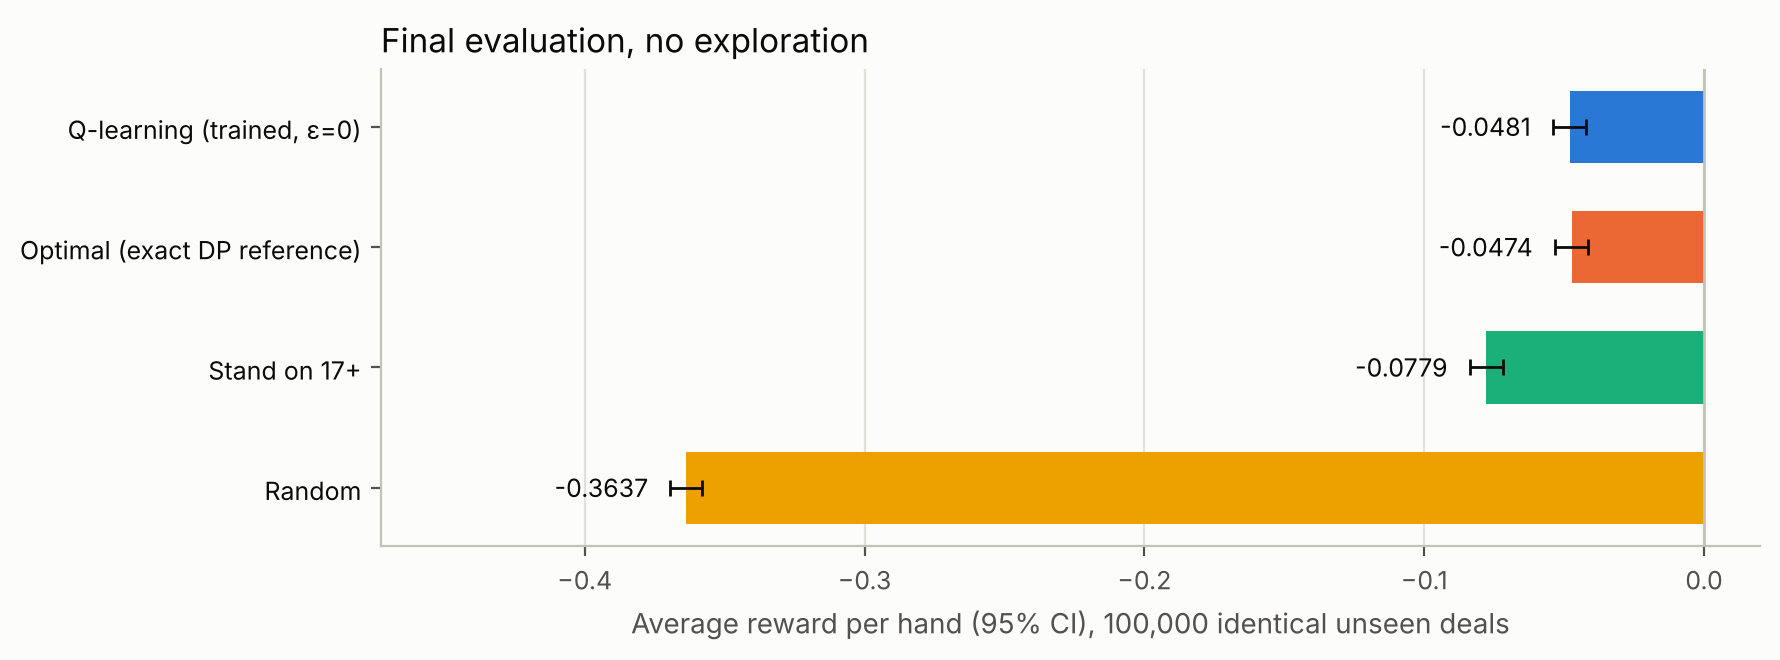

In [6]:
results = final_comparison(standard_policies(Q), CONFIG)
display(results[["avg_reward", "ci95_low", "ci95_high", "win_rate", "loss_rate", "push_rate"]])
plots.final_bars(results); plt.show()

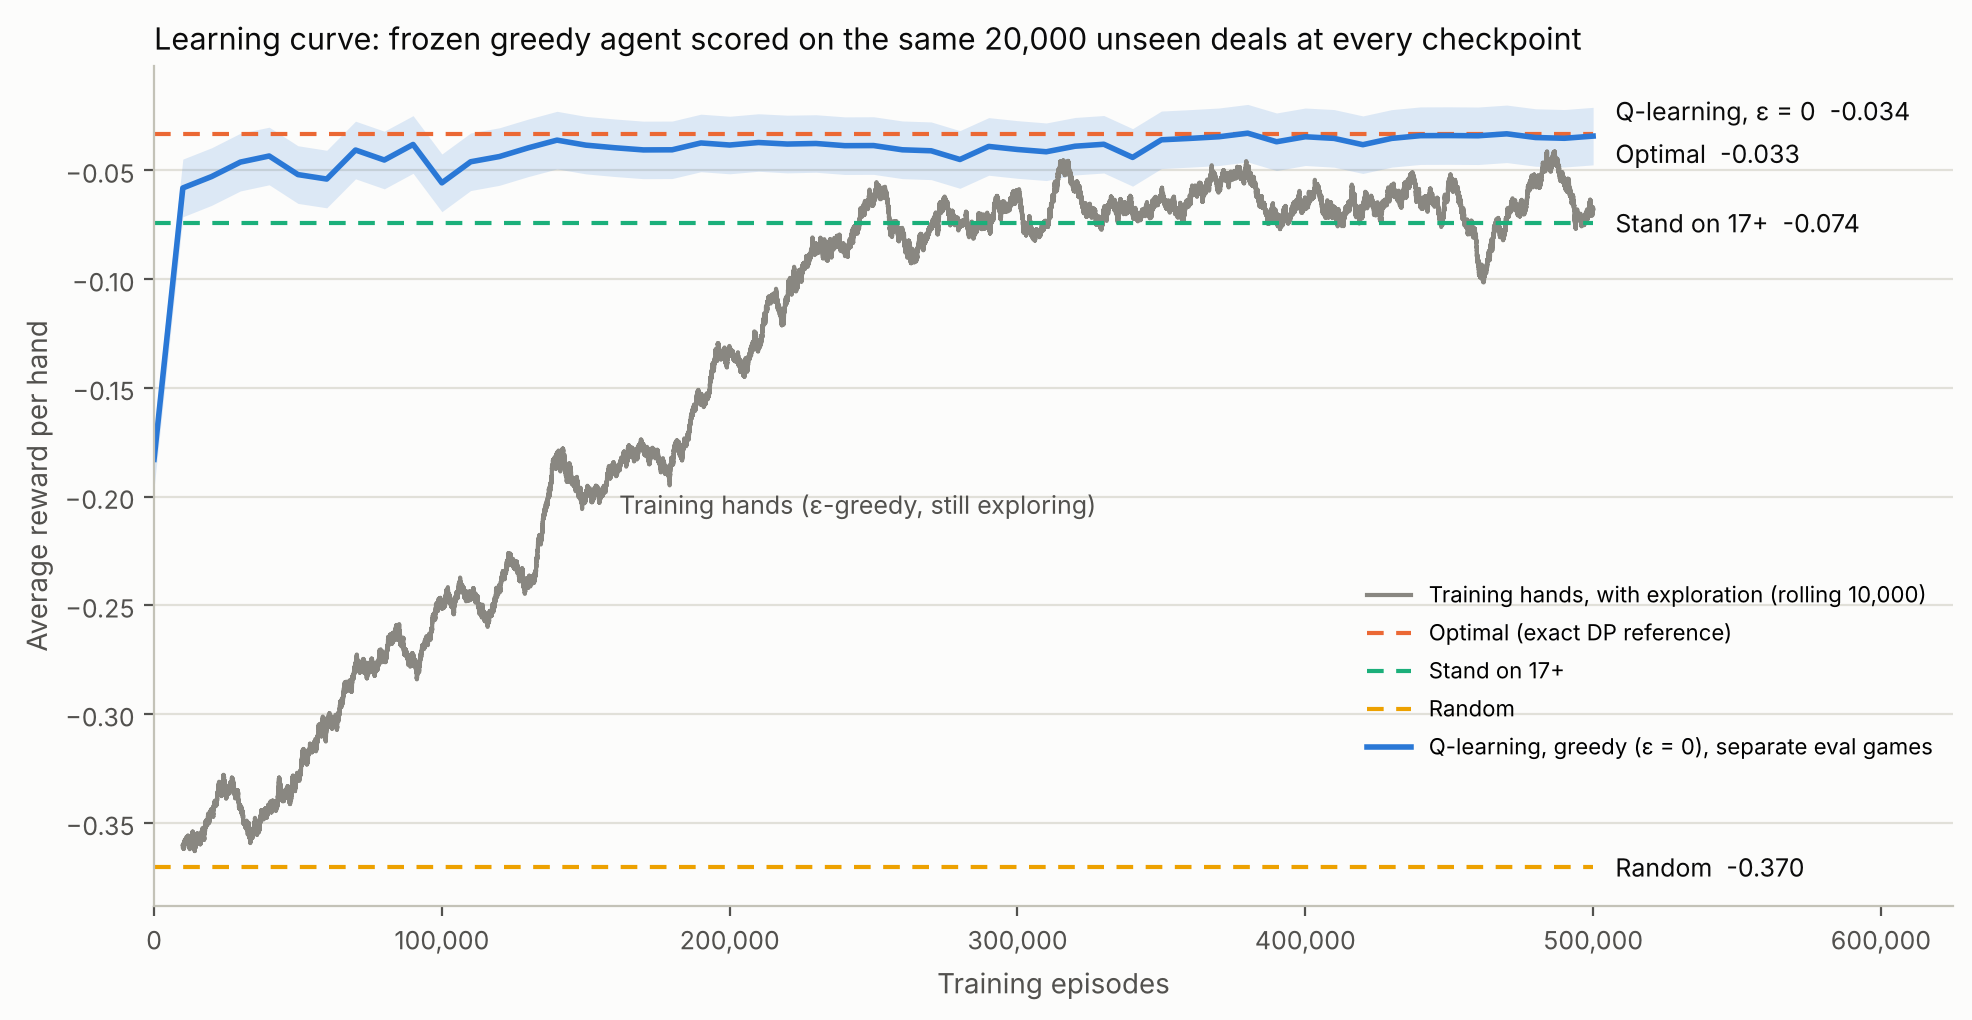

In [7]:
plots.learning_curve(curve, curve_refs, train_rewards); plt.show()

**Interpretation**

* At episode 0 the Q-table is all zeros, so the greedy agent stands on everything. After training it scores essentially the same as the exact optimal policy. The 95% intervals overlap almost completely on both the checkpoint deals and the final 100,000 deals.
* It clearly beats both comparison strategies: by about 0.03 reward per hand over "stand on 17+" (non-overlapping intervals) and by about 0.32 over random.
* The gray line is the reward earned **while training**. It stays below the blue line because ε-greedy keeps taking random actions. This is why evaluation has to be done separately with ε = 0 (the same exploration-vs-exploitation trade-off as HW4 Part VIII).
* An average reward below 0 is expected: no Hit/Stand-only strategy beats the dealer under these rules. The optimal expected value is about −0.047 per hand.

## Part 5 — What did the agent learn?

Each cell is the learned action. **✕** marks a state where it differs from the exact optimal action. The table below lists those states and how much each mistake actually costs ($|Q^*_{stand} - Q^*_{hit}|$).

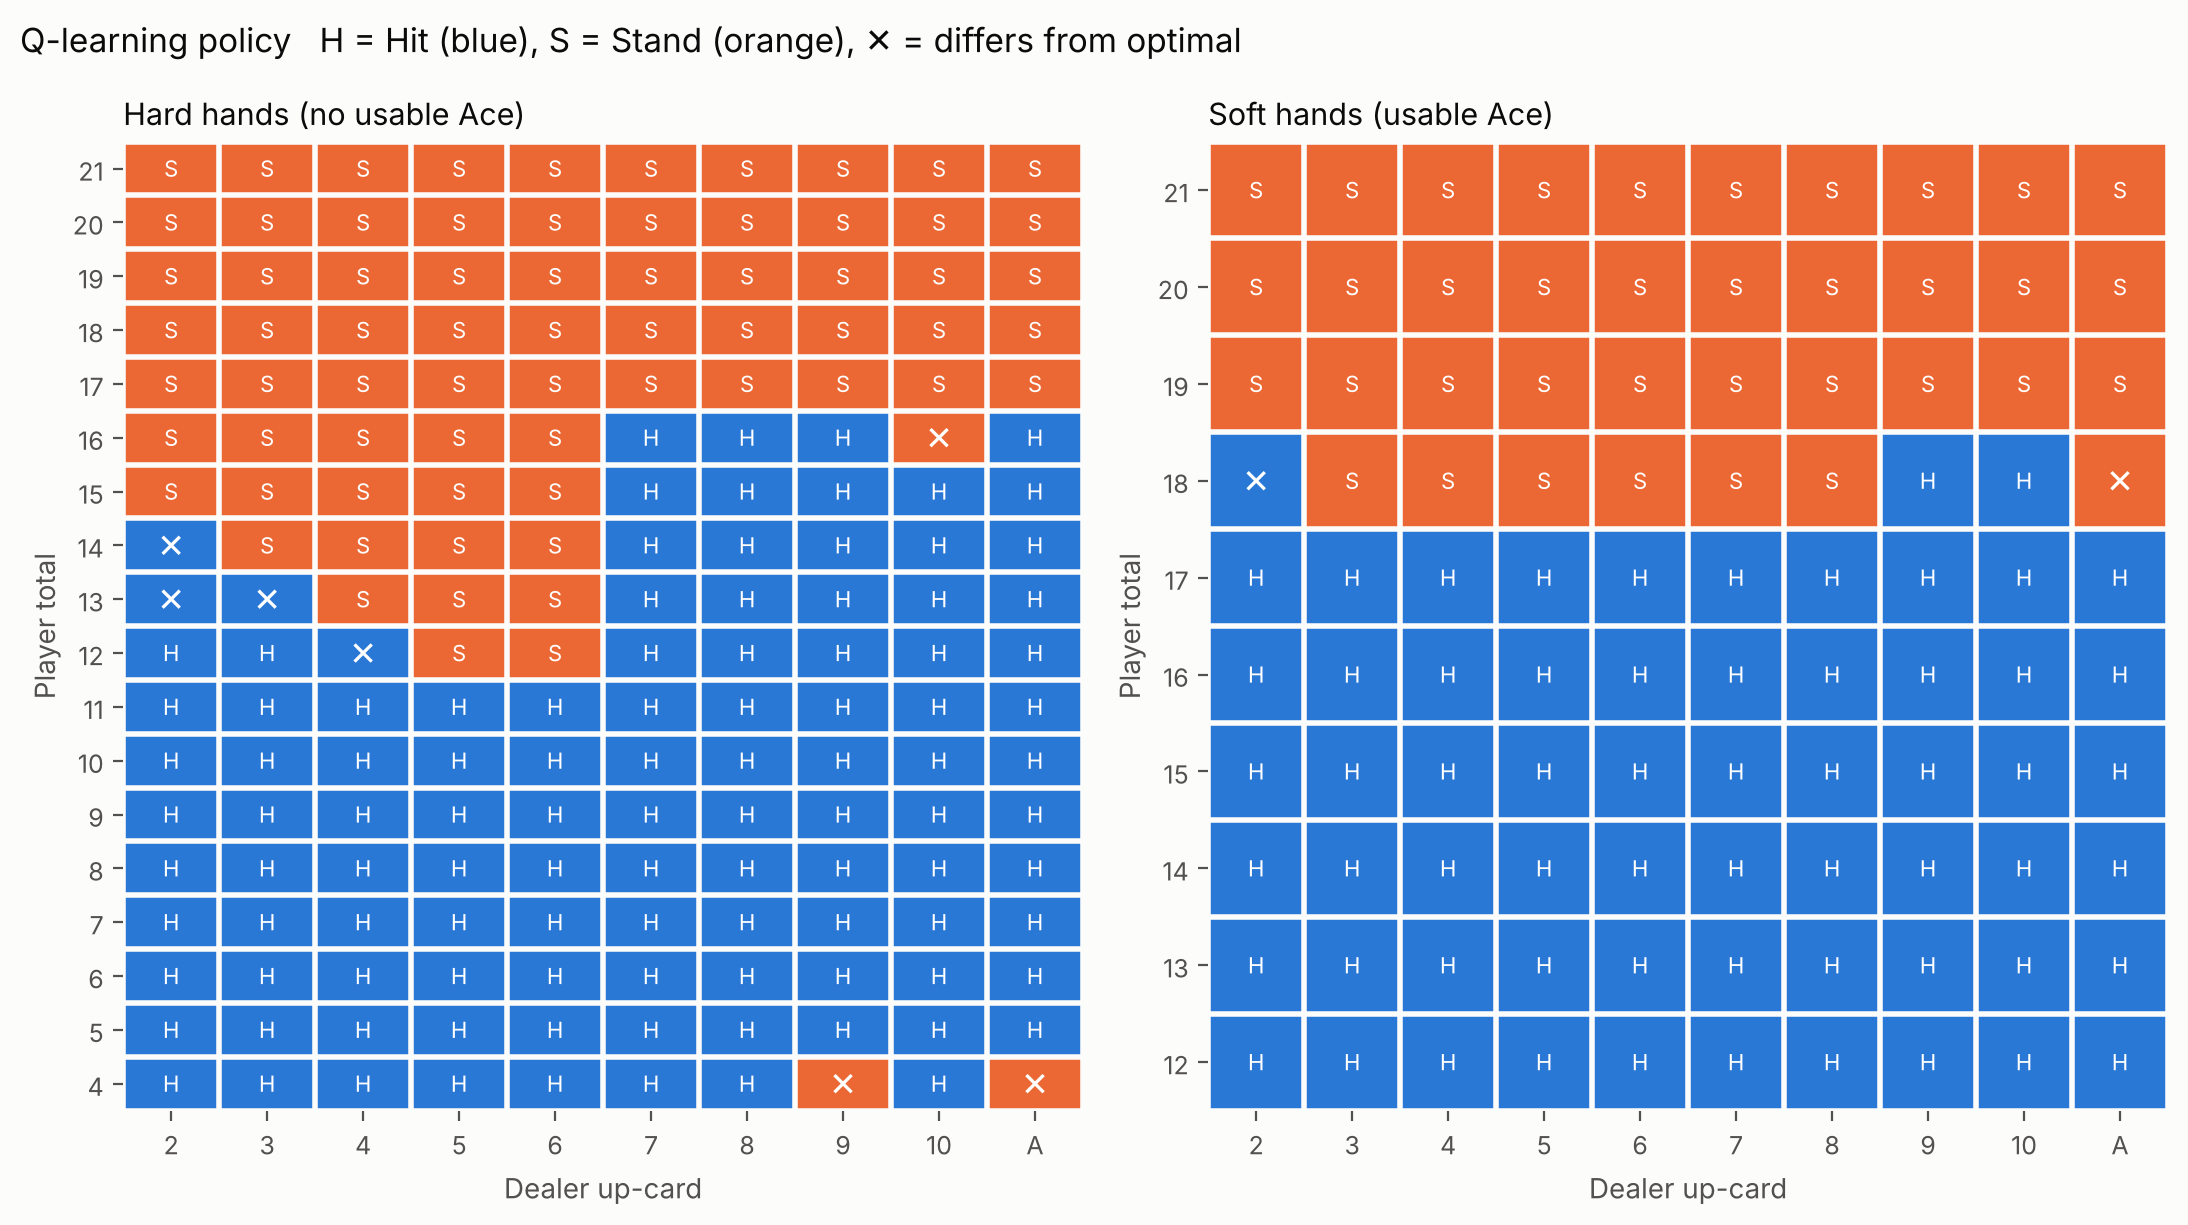

Agrees with the optimal action in 271 of 280 states.


,player_total,dealer_up,usable_ace,learned,optimal,Q*_stand,Q*_hit,cost_of_mistake
6,16,10,False,Stand,Hit,-0.5404,-0.5398,0.0006
2,12,4,False,Hit,Stand,-0.2111,-0.2135,0.0025
7,18,A,True,Stand,Hit,-0.1002,-0.0929,0.0073
3,13,2,False,Hit,Stand,-0.2928,-0.3078,0.0150
4,13,3,False,Hit,Stand,-0.2523,-0.2912,0.0390
8,18,2,True,Hit,Stand,0.1217,0.0629,0.0588
5,14,2,False,Hit,Stand,-0.2928,-0.3622,0.0694
1,4,9,False,Stand,Hit,-0.5431,-0.2407,0.3025
0,4,A,False,Stand,Hit,-0.6670,-0.2531,0.4139


In [8]:
learned = policy_from_q(Q)
plots.policy_maps(learned, optimal_policy(), "Q-learning policy"); plt.show()
dis = policy_disagreements(learned)
print(f"Agrees with the optimal action in {280 - len(dis)} of 280 states.")
display(dis.sort_values("cost_of_mistake"))

The learned chart reproduces the textbook strategy: stand on hard 17+, stand on 12–16 against a weak dealer card (2–6), hit 12–16 against 7–A, and hit soft 17 or below. The few disagreements fall into two groups:

1. **Near-ties:** hard 16 vs 10, hard 12–14 vs 2–4, and soft 18 vs A. In these states hitting and standing are worth almost the same, so the agent's small estimation errors can flip the choice.
2. **Rare states:** hard 4 can only come from a 2+2 deal (1 deal in 169). With a fixed α = 0.01 these Q-values are still near their starting value of 0. A per-state learning rate, α = 1/N(s,a), is a possible fix for the final project.

## Part 6 — Kaggle dataset: "900,000 Hands of BlackJack Results"

The dataset is used in two ways:

1. **Validate the simulator's dealer.** Compare the dealer bust rate for each up-card in 150,000 recorded rounds against the exact rate our rule implies.
2. **Offline Q-learning.** Turn each recorded hand into (s, a, r, s′) experiences and replay them through the **same update function**, without playing any new games.

`load_hands("auto")` uses `data/blkjckhands.csv` if it is present, downloads the file with `kagglehub` if Kaggle credentials are set up, and otherwise falls back to the 6,000-row sample in the repo.

Loaded 900,000 hands from blkjckhands.csv


,dataset_bust_rate,mis_scored_hands,dealer_hands,exact_bust_rate,difference
A,0.1880,390,8092,0.1665,0.0214
2,0.3549,202,11535,0.3536,0.0013
3,0.3774,116,11564,0.3739,0.0035
4,0.3868,49,11555,0.3945,-0.0076
5,0.4122,0,11674,0.4164,-0.0042
6,0.4156,0,11397,0.4232,-0.0075
7,0.2560,0,11455,0.2623,-0.0063
8,0.2487,0,11442,0.2447,0.0040
9,0.2249,0,11478,0.2284,-0.0036
10,0.2306,0,42548,0.2298,0.0008


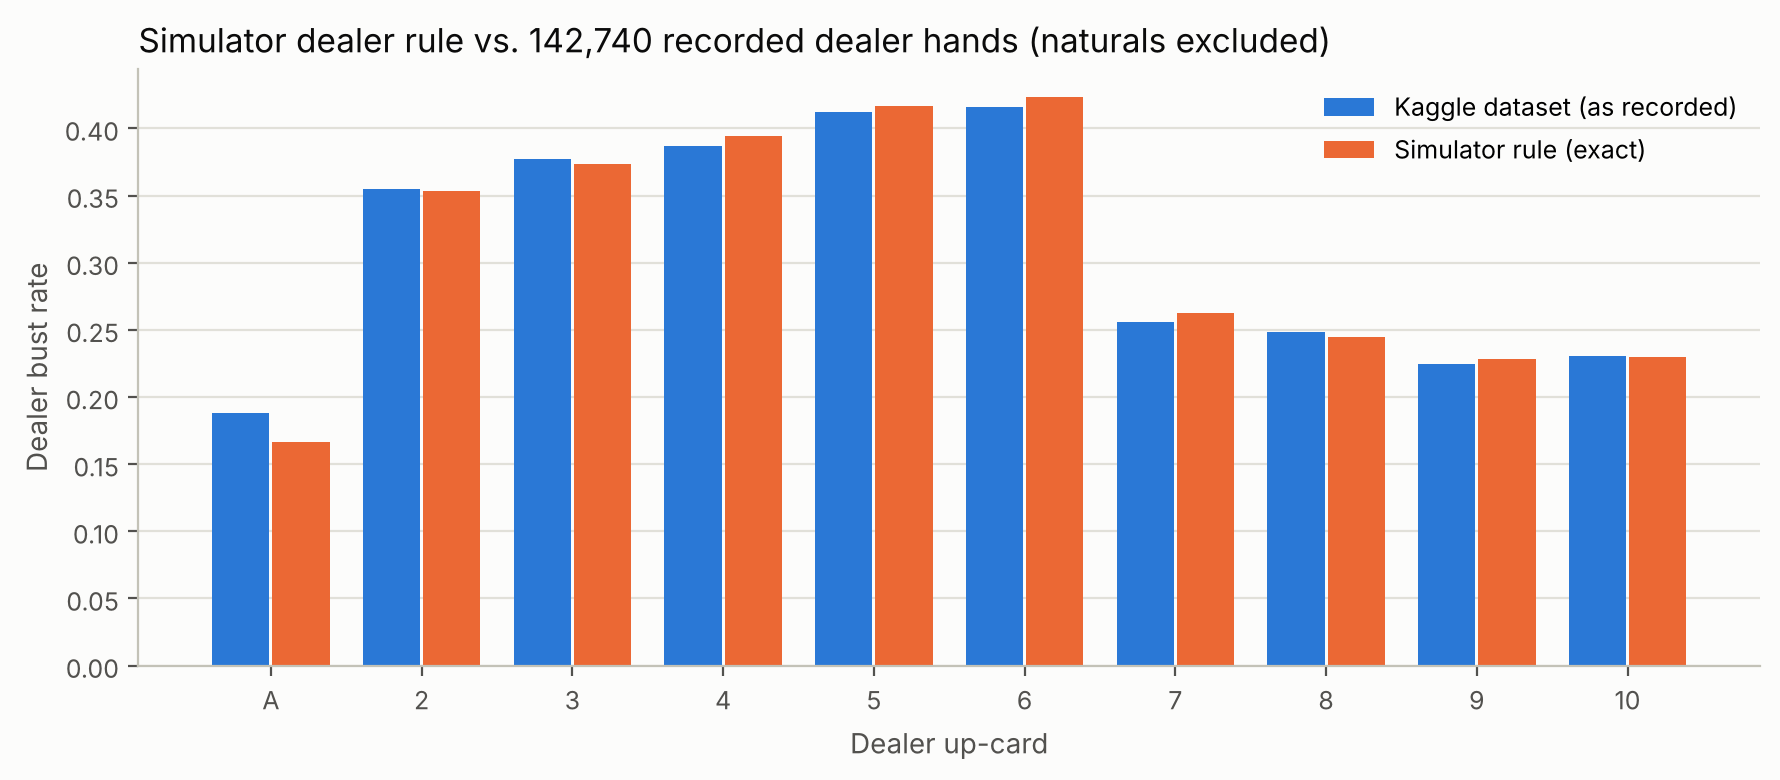

In [9]:
from blackjack_rl.optimal import dealer_final_distribution
df = dataset.load_hands("auto")
check = dataset.dealer_bust_by_upcard(df)
check["exact_bust_rate"] = [dealer_final_distribution(u)["bust"] for u in check.index]
check["difference"] = check["dataset_bust_rate"] - check["exact_bust_rate"]
check.index = ["A" if u == 1 else u for u in check.index]
display(check)
plots.dealer_check(check); plt.show()

**Result:** for up-cards 2–10 the recorded dealer matches our rule to within about one percentage point, which confirms the "stand on all 17s" rule. With an **Ace** up, the dataset busts about 2 points more often. The `mis_scored_hands` column explains why: in those hands the recorded total is wrong for the recorded cards. For example, A, A, 4, 6 should be 12 but is recorded as 22, a bust, because the dataset's generator never reduced the Ace from 11 to 1. These errors only happen when the dealer holds an Ace and draws low cards, which is why they cluster on Ace and low up-cards. Hands with mis-scored totals are excluded from offline training.

In [10]:
episodes, skipped = dataset.build_episodes(df)
n_trans = sum(len(e) for e in episodes)
print(f"{len(episodes):,} usable hands -> {n_trans:,} experiences (skipped {skipped:,}: naturals or mis-scored)")
print(f"Recorded players' own average reward: {sum(e[-1][2] for e in episodes) / len(episodes):+.4f}")

Q_off, seen = dataset.train_offline_q(episodes, passes=10, alpha=0.01)
off_policy = dataset.offline_policy(Q_off, seen)
both = [s for s in all_states() if seen[(s, "Hit")] and seen[(s, "Stand")]]
opt = optimal_policy()
print(f"States where the recorded players tried BOTH actions: {len(both)} of 280")
print(f"  offline-learned action matches optimal in {sum(off_policy(s) == opt(s) for s in both)} of them")

offline_results = final_comparison({"Offline Q-learning (dataset only)": off_policy,
                                    **standard_policies(Q)}, CONFIG)
display(offline_results[["avg_reward", "ci95_low", "ci95_high"]])

808,369 usable hands -> 1,240,169 experiences (skipped 91,631: naturals or mis-scored)
Recorded players' own average reward: -0.0542


States where the recorded players tried BOTH actions: 111 of 280
  offline-learned action matches optimal in 105 of them


,avg_reward,ci95_low,ci95_high
policy,,,
Offline Q-learning (dataset only),-0.0546,-0.0605,-0.0487
"Q-learning (trained, ε=0)",-0.0481,-0.0540,-0.0421
Optimal (exact DP reference),-0.0474,-0.0533,-0.0414
Stand on 17+,-0.0779,-0.0837,-0.0720
Random,-0.3637,-0.3694,-0.3581


**Interpretation:** learning only from recorded hands gets close to online Q-learning, within about 0.007 reward per hand, and picks the optimal action in most states where the recorded players tried **both** actions. But the players **never hit on hard 17+ and never stood on 11 or less**, so the dataset has nothing to say about those actions. A Q-value for an action that was never taken is just its starting 0, not a learned estimate. The offline policy therefore only chooses between actions that were actually observed. This is the HW4 Part VII lesson in data form: an agent can only learn about actions that someone actually tried, which is why online Q-learning needs exploration.

*Note: the dataset is a different game from our simulator (recorded payouts, a possibly finite shoe, and the scoring errors above), so the recorded players' own average is a reference, not a strict baseline.*

## Part 7 — Correctness verification

| # | Test (`tests/`) | Expected behavior | Why it matters |
|---|---|---|---|
| 1 | `test_q_update_matches_hand_calculation` | 12 vs 4, Hit → 16 (Q=−0.20, r=0, max Q′=−0.30, α=0.1, γ=1) → target −0.30, TD −0.10, Q −0.21 | The update matches the course equation |
| 2 | `test_terminal_transition_ignores_next_state` | Terminal target = r only, even if other Q-values are large | Bust or stand must not borrow future value |
| 3 | `test_hand_value_counts_aces_correctly` | A+6 = soft 17; A+6+10 = hard 17; A+A = 12 | State representation is correct |
| 4 | `test_dealer_stands_on_soft_17`, `test_dealer_hits_16` | Dealer draws on 16 and stands on soft 17 | The stated dealer rule is what the code does |
| 5 | `test_naturals_...`, `test_player_bust_is_immediate_loss` | +1 / −1 / 0 for naturals; bust = −1 and the dealer doesn't play | Rewards match the written rules |
| 6 | `test_simulated_dealer_matches_exact_probabilities` | Simulated dealer bust rate is within 0.5 points of the exact DP value | Simulator and DP model agree independently |
| 7 | `test_training_is_reproducible`, `test_evaluation_does_not_change_q_table` | Same seed → same Q-table; evaluation leaves Q unchanged | Reproducibility; evaluation really has no learning |
| 8 | `test_learned_policy_on_obvious_states` | Stand on hard 20–21, hit on hard 8–11 | The agent learned the obviously correct actions |
| 9 | `test_trained_agent_beats_baselines_on_separate_games` | random < stand-17 < Q-learning, and Q-learning is within 0.01 of optimal | The headline result holds on unseen games |
| 10 | `test_dataset.py` (4 tests) | Recorded hands convert to the right (s, a, r, s′); mis-scored hands are dropped | The dataset pipeline is correct |

In [11]:
import subprocess
out = subprocess.run([sys.executable, "-m", "pytest", "-v", "--no-header", "--color=no", "-p", "no:cacheprovider"],
                     cwd=Path.cwd().parent, capture_output=True, text=True)
print(out.stdout)

============================= test session starts ==============================
collecting ... collected 18 items

tests/test_agent.py::test_q_update_matches_hand_calculation PASSED       [  5%]
tests/test_agent.py::test_terminal_transition_ignores_next_state PASSED  [ 11%]
tests/test_agent.py::test_training_is_reproducible PASSED                [ 16%]
tests/test_agent.py::test_evaluation_does_not_change_q_table PASSED      [ 22%]
tests/test_agent.py::test_learned_policy_on_obvious_states PASSED        [ 27%]
tests/test_agent.py::test_trained_agent_beats_baselines_on_separate_games PASSED [ 33%]
tests/test_dataset.py::test_recorded_hand_becomes_hit_then_stand PASSED  [ 38%]
tests/test_dataset.py::test_recorded_bust_ends_with_minus_one PASSED     [ 44%]
tests/test_dataset.py::test_mis_scored_dealer_hand_is_skipped PASSED     [ 50%]
tests/test_dataset.py::test_sample_parses_into_valid_episodes PASSED     [ 55%]
tests/test_env.py::test_hand_value_counts_aces_correctly PASSED          [ 6

## Summary

* The Q-learning update follows the equation from HW4 Part VI and is checked against a hand-worked blackjack example.
* After 500,000 training hands, the greedy agent (ε = 0) averages about −0.048 per hand on 100,000 unseen deals. That is statistically the same as the exact optimal policy (about −0.047) and clearly better than "stand on 17+" (about −0.078) and random (about −0.364).
* It matches the optimal action in about 271 of 280 states. The misses are near-ties or very rare states.
* The Kaggle dataset confirmed the simulator's dealer rule for up-cards 2–10 and exposed an Ace-scoring error in the dataset itself. Offline learning from the dataset shows why exploration is needed.